# Where should the robotaxis wait? Demand-focused EDA and revised H1

**Phase 2 · ADS graded submission · Krish Sharma · prepared 15 November 2026**

**EDA** means exploring data to understand patterns and limitations before modelling.
**Zone** means a mapped taxi area. **Zone-hour** means one zone during one real hour.
**Hypothesis** means a claim tested against evidence. **Baseline** means a simple comparison.

**Revised H1:** eligible completed-trip request demand differs meaningfully across pickup
zones and hours. This user-approved change replaces the proposal's fare-per-minute H1
and is **pending team review** (`docs/decisions.md`). This notebook tests demand patterns,
not whether a profit strategy has won.

Our proposed robotaxi pricing is **common base charge + common rate × passenger miles**.
There is **no passenger time charge** and no zone-dependent rate. Numeric rates are not
chosen here. Journey duration still determines vehicle availability. Historical fares
remain descriptive source measurements, not our simulated prices or robotaxi profit.

### Scope and reproducibility
- Use the verified Phase 1 release and **January–August 2024 only**; no sampled zone-hours.
- September–October is reserved for validation; November–December for the final test;
  January 2025 for drift. We verify file hashes, but do not analyse held-out outcomes.
- Keep the existing **1-minute–3-hour** cleaning range. Do not rerun or change Phase 1.
- Counts describe **eligible completed Uber/Lyft trips**, not all requested or unserved rides.
- Read Markdown before each cell. Finish by restarting the kernel and running every cell.

### Setup
Select a Python environment with the exact packages in `notebooks/requirements-eda.txt`.
On this machine the working EDA interpreter is `.venv/eda/Scripts/python.exe`.
Run from the repository root or its `notebooks` directory. No Spark/Java is required.
Obtain and verify `phase1-2024-v1` using `docs/phase1_handover.md` first. This notebook
does not download or install anything and writes only ignored `data/eda/` outputs.


## 1. Libraries, configuration, and assumptions fixed before results

PyArrow reads only the required Parquet columns and training rows. Pandas/NumPy calculate
summaries. Matplotlib/Seaborn draw charts. Shapely reads map boundaries. SciPy implements
the Friedman repeated-measures test; we use weeks as blocks, not individual trips.

The final three training months form an **internal development window** for historical
forecasts, not the project's held-out test. No trained model is selected here.

For H1 we declare an **illustrative practical threshold** of 10% share mismatch from a
uniform distribution. It is an operational convention, not a universal statistical law
or a guaranteed profit gain. We show sensitivity at 5%, 10%, and 20%, without choosing a
threshold after looking at results. Seeded two-week block resampling measures uncertainty
in descriptive demand shares; inference is exploratory and depends on time stability.


In [1]:
import hashlib
import json
import os
import sys
from datetime import UTC, datetime
from importlib import metadata
from pathlib import Path

ROOT = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
             if (folder / 'repo_instructions.md').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from this repository or its notebooks directory.')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'data/eda/plot-cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.collections import PatchCollection
from matplotlib.patches import PathPatch
from matplotlib.path import Path as PlotPath
from scipy import stats
from shapely import from_wkb
from shapely.geometry.polygon import orient

RELEASE = ROOT / 'data/releases/phase1-2024-v1'
OUTPUT = ROOT / 'data/eda/phase2-training'
OUTPUT.mkdir(parents=True, exist_ok=True)
TRAIN_START = '2024-01-01'
TRAIN_END = '2024-09-01'
DEVELOPMENT_START = '2024-06-01'
RANDOM_SEED = 240514
BOOTSTRAP_REPEATS = 2000
PRACTICAL_SHARE_GAP = 0.10
ALPHA = 0.05
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 16)
VERSIONS = {name: metadata.version(name) for name in
            ['pyarrow', 'pandas', 'numpy', 'matplotlib', 'seaborn', 'shapely', 'scipy']}
print('Python:', sys.version.split()[0], '| Packages:', VERSIONS)
print('Exploration: [', TRAIN_START, ',', TRAIN_END, ') New York civil dates')


Python: 3.12.14 | Packages: {'pyarrow': '24.0.0', 'pandas': '3.1.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'shapely': '2.2.0', 'scipy': '1.18.1'}
Exploration: [ 2024-01-01 , 2024-09-01 ) New York civil dates


### Small, result-critical notebook functions

These functions keep path handling, missing values, historical alignment, and weekly
summaries consistent. Their behaviour is tested separately with small synthetic inputs.
They stay inside the notebook so the analysis is readable from top to bottom.


In [2]:
def safe_project_path(root, relative):
    '''Resolve a relative release path inside the repo; reject paths escaping it.'''
    relative = Path(relative)
    if relative.is_absolute():
        raise ValueError('Portable release paths must be relative.')
    resolved = (root / relative).resolve()
    if not resolved.is_relative_to(root.resolve()):
        raise ValueError('Release path escapes the project.')
    return resolved


def divide_valid(numerator, denominator):
    '''Divide where a positive denominator exists; preserve unknown values as NaN.'''
    return numerator.div(denominator.where(denominator > 0))


def matching_week_forecasts(wide):
    '''Return last-week and strict four-week forecasts on a unique civil-hour index.'''
    if not wide.index.is_unique or not wide.index.is_monotonic_increasing:
        raise ValueError('Use sorted unique civil hours; resolve DST folds explicitly.')
    if not isinstance(wide.index, pd.DatetimeIndex) or wide.index.tz is not None:
        raise ValueError('Use offset-free New York civil-hour keys, not UTC shifts.')
    lags = []
    for weeks in range(1, 5):
        lag = wide.reindex(wide.index - pd.Timedelta(weeks=weeks)).copy()
        lag.index = wide.index
        lags.append(lag)
    stack = np.stack([frame.to_numpy(dtype=float) for frame in lags])
    four = np.mean(stack, axis=0)  # any missing week remains missing, never zero
    return lags[0], pd.DataFrame(four, index=wide.index, columns=wide.columns)


def complete_week_matrices(demand_wide):
    '''Build matched zone/hour mean rates from complete Monday–Sunday weeks only.'''
    week_start = demand_wide.index.normalize() - pd.to_timedelta(demand_wide.index.day_of_week, unit='D')
    zone_rows, hour_rows, kept = [], [], []
    for start in pd.DatetimeIndex(week_start.unique()).sort_values():
        block = demand_wide.loc[week_start == start]
        expected = pd.date_range(start, periods=168, freq='h')
        if not block.index.equals(expected) or block.isna().any().any():
            continue
        zone_rows.append(block.mean(axis=0).to_numpy())
        hour_rows.append(block.sum(axis=1).groupby(block.index.hour).mean().reindex(range(24)).to_numpy())
        kept.append(start)
    if len(kept) < 12:
        raise ValueError('Need at least 12 complete matched weeks for the planned exploratory H1 test.')
    return np.asarray(zone_rows), np.asarray(hour_rows), pd.DatetimeIndex(kept)


def share_mismatch(values):
    '''Return share mass that differs from equal shares; not a fleet profit measure.'''
    values = np.asarray(values, dtype=float)
    if not np.isfinite(values).all() or (values < 0).any() or values.sum() <= 0:
        raise ValueError('Shares require finite nonnegative values with positive total.')
    shares = values / values.sum()
    return float(0.5 * np.abs(shares - 1 / len(shares)).sum())


def block_share_interval(matrix, repeats=2000, block_length=2, seed=240514, week_starts=None):
    '''Resample consecutive weekly blocks; return a 95% interval for mean-share mismatch.'''
    matrix = np.asarray(matrix, dtype=float)
    if matrix.ndim != 2 or len(matrix) < block_length or block_length < 1:
        raise ValueError('Need a weekly matrix and a valid block length.')
    candidates = np.arange(len(matrix) - block_length + 1)
    if week_starts is not None:
        weeks = pd.DatetimeIndex(week_starts)
        if len(weeks) != len(matrix):
            raise ValueError('Week dates must match matrix rows.')
        candidates = np.asarray([start for start in candidates
            if all(weeks[start + step] - weeks[start] == pd.Timedelta(weeks=step)
                   for step in range(block_length))])
        if not len(candidates):
            raise ValueError('No consecutive complete weekly blocks available.')
    rng = np.random.default_rng(seed)
    estimates = []
    for _ in range(repeats):
        starts = rng.choice(candidates, size=int(np.ceil(len(matrix) / block_length)))
        indices = np.concatenate([np.arange(start, start + block_length) for start in starts])[:len(matrix)]
        estimates.append(share_mismatch(matrix[indices].mean(axis=0)))
    return tuple(float(value) for value in np.quantile(estimates, [0.025, 0.975]))


def forecast_scores(actual, predicted):
    '''Calculate errors on an already aligned common finite evaluation sample.'''
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    if actual.shape != predicted.shape or actual.size == 0:
        raise ValueError('Forecast shapes must match and contain observations.')
    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError('Do not silently score missing forecasts or targets.')
    error = predicted - actual
    total = actual.sum()
    return {'MAE_requests': float(np.abs(error).mean()),
            'RMSE_requests': float(np.sqrt((error ** 2).mean())),
            'WAPE_percent': float(100 * np.abs(error).sum() / total) if total > 0 else None,
            'bias_requests': float(error.mean())}


## 2. Verify the release and load only training observations

SHA-256 is a file fingerprint: a changed byte changes the fingerprint. Check every shared
file against the release manifest before analysis. This verifies local file identity,
not the correctness of the original data. The manifest also covers held-out partitions;
hashing their bytes is not using their outcomes to choose a model.

The portable table index controls loading. We require the training-period filter at the
Parquet scan, then verify civil date bounds, unique zone-hour keys, and zone membership.


In [3]:
index_path = RELEASE / 'metadata/table_index.json'
manifest_path = RELEASE / 'metadata/file_manifest.json'
if not index_path.is_file() or not manifest_path.is_file():
    raise FileNotFoundError('Prepared Phase 1 release missing. Obtain it using docs/phase1_handover.md first.')
table_index = json.loads(index_path.read_text(encoding='utf-8'))
file_manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
for record in file_manifest:
    path = safe_project_path(ROOT, record['path'])
    if path.stat().st_size != record['bytes']:
        raise ValueError(f'Release size mismatch: {path.name}')
    with path.open('rb') as stream:
        if hashlib.file_digest(stream, 'sha256').hexdigest() != record['sha256']:
            raise ValueError(f'Release checksum mismatch: {path.name}')
print('Verified shared files:', len(file_manifest))

hours_dataset = ds.dataset(safe_project_path(ROOT, table_index['zone_hour']['path']),
                           format='parquet', partitioning='hive')
columns = ['zone_id', 'hour_start_utc', 'event_date_nyc', 'hour_nyc', 'period_label',
           'request_count', 'request_count_observed', 'request_coverage_complete',
           'pickup_count', 'dropoff_count', 'pickup_coverage_complete', 'dropoff_coverage_complete',
           'valid_fare_count', 'valid_tolls_count', 'monetary_trip_count', 'passenger_measure_count',
           'valid_base_fare_sum_usd', 'valid_tolls_sum_usd', 'passenger_miles_sum', 'passenger_minutes_sum',
           'mean_passenger_miles', 'mean_passenger_minutes', 'mean_base_fare_usd',
           'mean_fare_per_trip_minute_usd', 'temperature_c', 'precipitation_previous_hour_mm',
           'wind_metres_per_second', 'visibility_metres', 'has_primary_weather',
           'is_federal_holiday', 'holiday_name', 'has_verified_holiday_calendar']
missing_columns = sorted(set(columns) - set(hours_dataset.schema.names))
if missing_columns:
    raise ValueError(f'Unexpected release schema; missing columns: {missing_columns}')
hours = hours_dataset.to_table(columns=columns, filter=ds.field('period_label') == 'train').to_pandas()
hours['hour_start_utc'] = pd.to_datetime(hours['hour_start_utc'], utc=True)
hours['event_date_nyc'] = pd.to_datetime(hours['event_date_nyc'])
hours['civil_hour'] = hours['hour_start_utc'].dt.tz_convert('America/New_York').dt.tz_localize(None)
assert hours['period_label'].eq('train').all()
assert hours['event_date_nyc'].ge(TRAIN_START).all() and hours['event_date_nyc'].lt(TRAIN_END).all()
assert not hours.duplicated(['zone_id', 'hour_start_utc']).any()
assert hours['civil_hour'].dt.normalize().eq(hours['event_date_nyc']).all()
zones = ds.dataset(safe_project_path(ROOT, table_index['zones']['path']), format='parquet').to_table().to_pandas()
assert len(zones) == 263 and zones['zone_id'].is_unique
assert set(hours['zone_id']) == set(zones['zone_id'])
before_zone_join = len(hours)
hours = hours.merge(zones[['zone_id', 'zone_name', 'borough', 'is_airport']],
                    on='zone_id', how='left', validate='many_to_one')
assert len(hours) == before_zone_join
print('Zone-name join rows:', before_zone_join, '->', len(hours))
assert hours['request_count'].notna().equals(hours['request_coverage_complete'].astype(bool))
assert (hours.loc[hours['request_count'].notna(), 'request_count'] >= 0).all()
wide = hours.pivot(index='civil_hour', columns='zone_id', values='request_count').sort_index()
print(f'Training data: {len(hours):,} zone-hours; {len(wide):,} real hours; {len(zones)} zones.')
print('Dates:', hours['event_date_nyc'].min().date(), 'to', hours['event_date_nyc'].max().date())
print('Approximate selected-table memory (MB):', round(hours.memory_usage(deep=True).sum() / 1e6, 1))


Verified shared files: 1183


Zone-name join rows: 1539865 -> 1539865


Training data: 1,539,865 zone-hours; 5,855 real hours; 263 zones.
Dates: 2024-01-01 to 2024-08-31
Approximate selected-table memory (MB): 407.2


## 3. Data quality: missing is different from zero

An incomplete hour must not become zero demand. Monetary summaries have separate valid
denominators: a trip can support demand analysis while its fare is unusable. Display
missingness before choosing chart inputs. We keep source nulls, including trace rain.


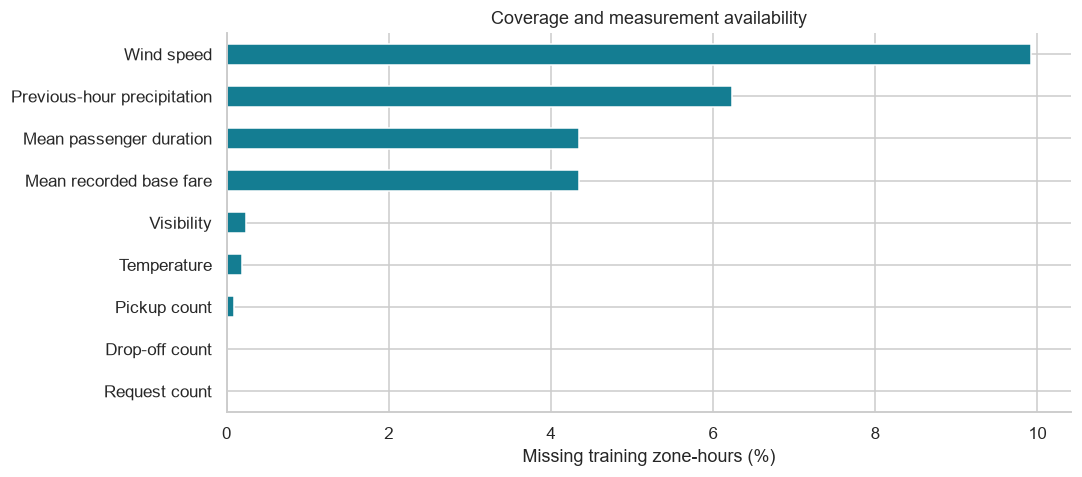

Incomplete request zone-hours: 0
Covered zero-request zone-hours: 66983
Unavailable primary-weather zone-hours: 2367
Unavailable verified-calendar zone-hours: 0


,zone_hours,covered_request_hours,observed_requests
month,,,
2024-01,195672,195672,19468463
2024-02,183048,183048,19153443
2024-03,195409,195409,21093564
2024-04,189360,189360,19551868
2024-05,195672,195672,20511578
2024-06,189360,189360,19929767
2024-07,195672,195672,18990552
2024-08,195672,195672,18942758


**Interpretation:** null hourly monetary means can mean no valid contributing trips, not a lost source hour. Use counts and coverage flags to distinguish these cases. Weather percentages above count zone-hours: the same city station is repeated across zones.

In [4]:
quality_columns = ['request_count', 'pickup_count', 'dropoff_count', 'mean_base_fare_usd',
                   'mean_passenger_minutes', 'temperature_c', 'precipitation_previous_hour_mm',
                   'wind_metres_per_second', 'visibility_metres']
missing_percent = hours[quality_columns].isna().mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
quality_labels = {'request_count': 'Request count', 'pickup_count': 'Pickup count', 'dropoff_count': 'Drop-off count',
                  'mean_base_fare_usd': 'Mean recorded base fare', 'mean_passenger_minutes': 'Mean passenger duration',
                  'temperature_c': 'Temperature', 'precipitation_previous_hour_mm': 'Previous-hour precipitation',
                  'wind_metres_per_second': 'Wind speed', 'visibility_metres': 'Visibility'}
missing_percent.rename(index=quality_labels).plot.barh(ax=ax, color='#147d92')
ax.set(xlabel='Missing training zone-hours (%)', title='Coverage and measurement availability')
plt.tight_layout(); plt.show()
print('Incomplete request zone-hours:', int((~hours['request_coverage_complete']).sum()))
print('Covered zero-request zone-hours:', int((hours['request_count'] == 0).sum()))
print('Unavailable primary-weather zone-hours:', int((~hours['has_primary_weather']).sum()))
print('Unavailable verified-calendar zone-hours:', int((~hours['has_verified_holiday_calendar']).sum()))
coverage_by_month = hours.assign(month=hours['event_date_nyc'].dt.to_period('M').astype(str)).groupby('month').agg(
    zone_hours=('zone_id', 'size'), covered_request_hours=('request_count', 'count'),
    observed_requests=('request_count', lambda values: values.sum(min_count=1)))
display(coverage_by_month)
display(Markdown('**Interpretation:** null hourly monetary means can mean no valid contributing trips, '
                 'not a lost source hour. Use counts and coverage flags to distinguish these cases. '
                 'Weather percentages above count zone-hours: the same city station is repeated across zones.'))


### Provider exclusions and unresolved times

A provider is Uber/Lyft's service licence. Cleaning removed some trips whose request time
was not before pickup. Compare exclusion counts to matching input counts, never compare
raw exclusions alone. Keep request-hour and pickup-hour views separate; they are two
views of records, not independent trips to add together. An unresolved DST time is not
silently assigned a different hour.


In [5]:
provider_dataset = ds.dataset(safe_project_path(ROOT, table_index['provider_exclusions']['path']), format='parquet')
provider_filter = ((ds.field('recorded_civil_hour') >= pa.scalar(datetime(2024, 1, 1)))
                   & (ds.field('recorded_civil_hour') < pa.scalar(datetime(2024, 9, 1))))
provider_parts = []
for batch in provider_dataset.scanner(columns=['service_license', 'time_basis', 'input_count',
                                               'sequential_request_order_exclusions'],
                                      filter=provider_filter, batch_size=100000).to_batches():
    part = batch.to_pandas()
    provider_parts.append(part.groupby(['service_license', 'time_basis'], dropna=False)[
        ['input_count', 'sequential_request_order_exclusions']].sum())
provider_summary = pd.concat(provider_parts).groupby(level=[0, 1], dropna=False).sum()
provider_summary['exclusion_percent'] = 100 * divide_valid(
    provider_summary['sequential_request_order_exclusions'], provider_summary['input_count'])
display(provider_summary)
unresolved_dataset = ds.dataset(safe_project_path(ROOT, table_index['unresolved_event_times']['path']), format='parquet')
unresolved = unresolved_dataset.to_table(filter=(ds.field('event_date_nyc') >= pa.scalar(datetime(2024, 1, 1).date()))
    & (ds.field('event_date_nyc') < pa.scalar(datetime(2024, 9, 1).date())),
    columns=['event_type', 'time_status', 'event_count']).to_pandas()
display(unresolved.groupby(['event_type', 'time_status'])['event_count'].sum().rename('unresolved_eligible_events').to_frame())
display(Markdown('**Limitation:** these exclusions may affect the demand proxy differently by provider. '
                 'Their cause and bias direction are not established. Missing event dates cannot be '
                 'assigned to the training period and are outside the dated summaries above.'))


input_count  \
service_license time_basis                           
HV0003          recorded_pickup_hour     118300710   
                recorded_request_hour    118302654   
HV0005          recorded_pickup_hour      40875284   
                recorded_request_hour     40875975   

                                       sequential_request_order_exclusions  \
service_license time_basis                                                   
HV0003          recorded_pickup_hour                                775471   
                recorded_request_hour                               775465   
HV0005          recorded_pickup_hour                                692141   
                recorded_request_hour                               692145   

                                       exclusion_percent  
service_license time_basis                                
HV0003          recorded_pickup_hour            0.655508  
                recorded_request_hour           0.655492  
HV0005          recorded_pickup_hour            1.693300  
                recorded_request_hour           1.693281

,,unresolved_eligible_events
event_type,time_status,
pickup,nonexistent,78


**Limitation:** these exclusions may affect the demand proxy differently by provider. Their cause and bias direction are not established. Missing event dates cannot be assigned to the training period and are outside the dated summaries above.

## 4. Demand over time

Use city totals only when every zone has coverage. Normalise monthly comparisons by
covered zone-hours because months have different lengths. New York's spring DST day has
23 real hours; we do not invent the missing civil hour or compare its total to a normal
24-hour day without adjustment.


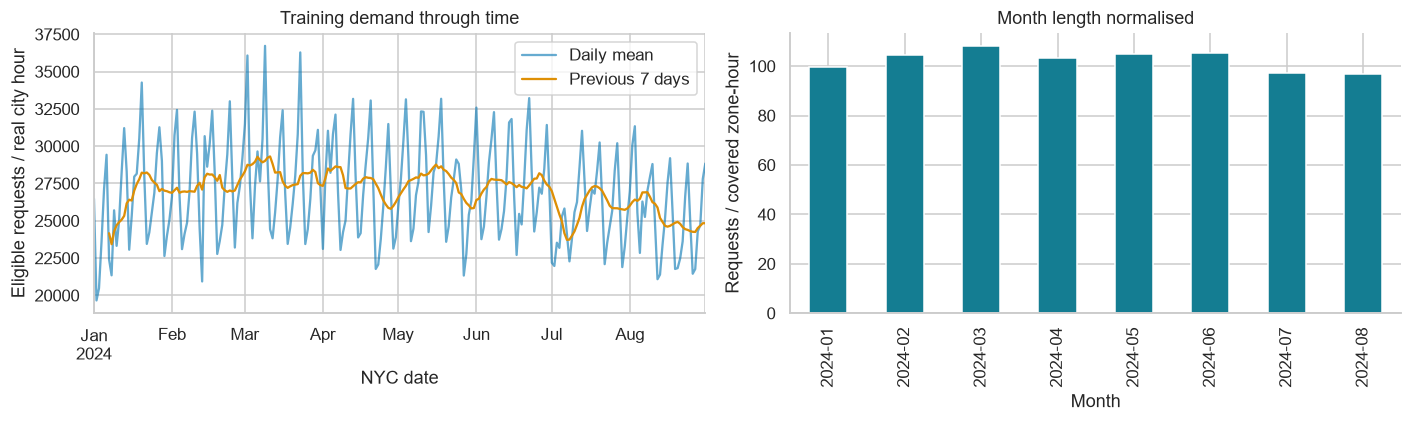

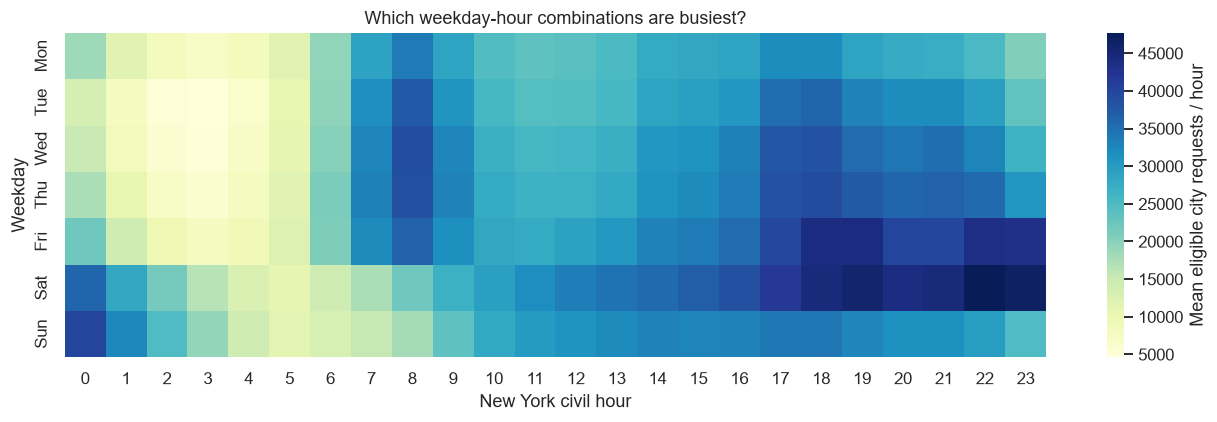

**Measured finding:** the largest mean weekday-hour cell is **Saturday at 22:00**, averaging **47,676** eligible city requests. This is descriptive training evidence, not a future forecast.

In [6]:
city = hours.groupby('hour_start_utc').agg(
    observed_city_requests=('request_count', lambda values: values.sum(min_count=1)),
    covered_zones=('request_count', 'count'), date=('event_date_nyc', 'first'),
    hour=('hour_nyc', 'first'), temperature_c=('temperature_c', 'first'),
    rain_mm=('precipitation_previous_hour_mm', 'first'),
    holiday=('is_federal_holiday', 'first'), holiday_name=('holiday_name', 'first'))
city['requests'] = city['observed_city_requests'].where(city['covered_zones'] == len(zones))
city['civil_hour'] = city.index.tz_convert('America/New_York').tz_localize(None)
city['weekday'] = city['date'].dt.day_of_week
city['month'] = city['date'].dt.month
daily = city.groupby('date').agg(requests=('requests', lambda values: values.sum(min_count=1)),
    covered_hours=('requests', 'count'), real_hours=('requests', 'size'),
    holiday=('holiday', 'first'), holiday_name=('holiday_name', 'first'))
daily['requests_per_hour'] = divide_valid(daily['requests'], daily['covered_hours'])
daily.loc[daily['covered_hours'] != daily['real_hours'], ['requests', 'requests_per_hour']] = np.nan
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
daily['requests_per_hour'].plot(ax=axes[0], alpha=.6, label='Daily mean')
daily['requests_per_hour'].rolling(7, min_periods=7).mean().plot(ax=axes[0], label='Previous 7 days')
axes[0].set(title='Training demand through time', ylabel='Eligible requests / real city hour', xlabel='NYC date')
axes[0].legend()
monthly_rate = divide_valid(coverage_by_month['observed_requests'], coverage_by_month['covered_request_hours'])
monthly_rate.plot.bar(ax=axes[1], color='#147d92')
axes[1].set(title='Month length normalised', ylabel='Requests / covered zone-hour', xlabel='Month')
plt.tight_layout(); plt.show()
weekday_hour = city.pivot_table(index='weekday', columns='hour', values='requests', aggfunc='mean').reindex(range(7))
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(weekday_hour, ax=ax, cmap='YlGnBu', yticklabels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'],
            cbar_kws={'label': 'Mean eligible city requests / hour'})
ax.set(title='Which weekday-hour combinations are busiest?', xlabel='New York civil hour', ylabel='Weekday')
plt.tight_layout(); plt.show()
peak_weekday, peak_hour = np.unravel_index(np.nanargmax(weekday_hour.to_numpy()), weekday_hour.shape)
display(Markdown(f'**Measured finding:** the largest mean weekday-hour cell is '
                 f'**{["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"][peak_weekday]} '
                 f'at {peak_hour:02d}:00**, averaging **{weekday_hour.iloc[peak_weekday, peak_hour]:,.0f}** eligible '
                 'city requests. This is descriptive training evidence, not a future forecast.'))


## 5. Geographic concentration and the equal-placement question

Compare mean requests per covered hour, not unnormalised counts if coverage differs.
Airports and Newark remain visible, not silently removed. Map colours use a log scale
so quieter zones are still visible. Maps use the released boundaries, with no web tiles.

If demand is uneven, equal car placement may be mismatched. It does not follow that
profit must improve: vehicle travel, idle time, fleet size and constraints still matter.


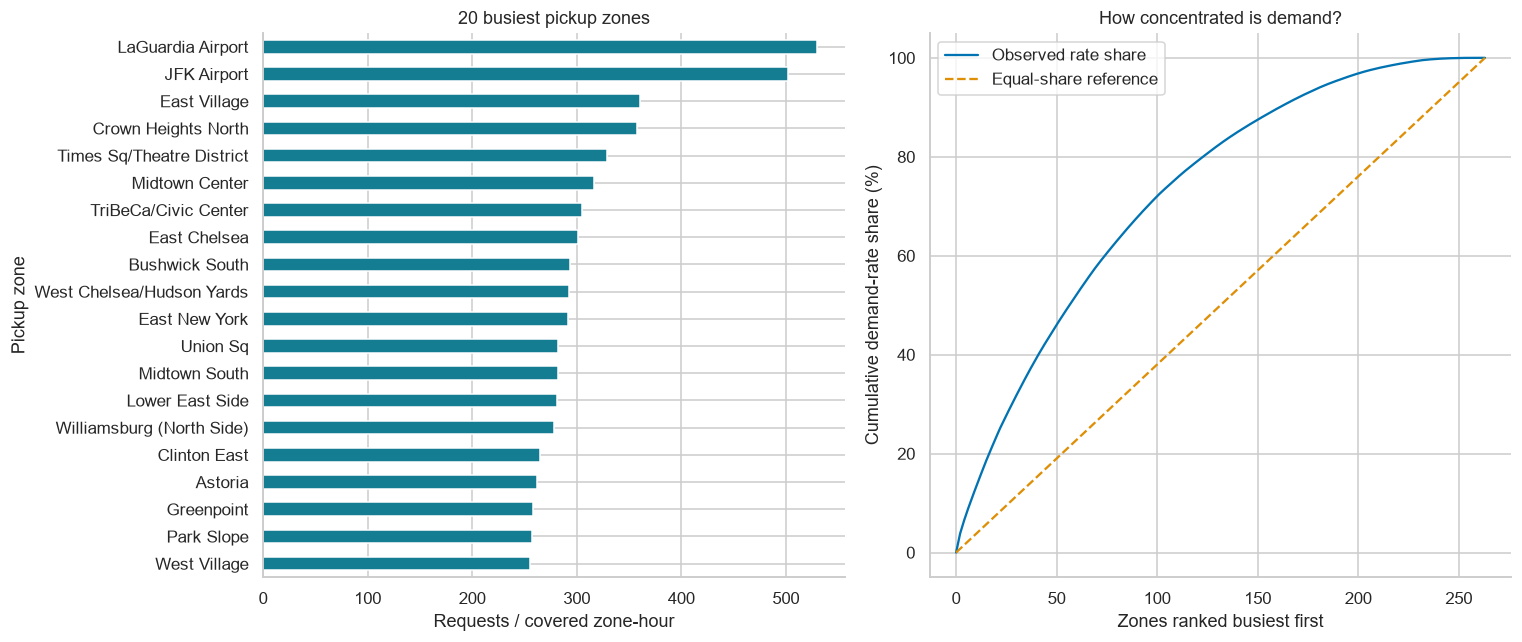

Top 10 of 263 zones account for 13.33% of summed mean demand rates.


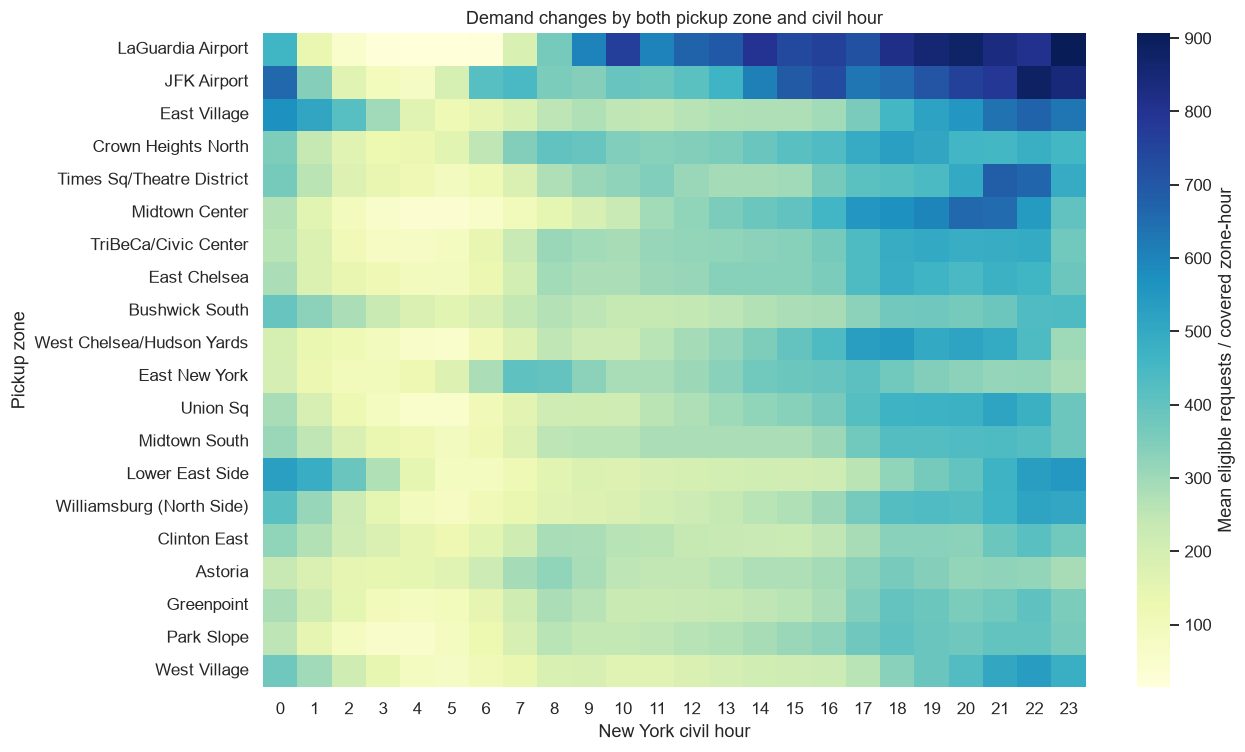

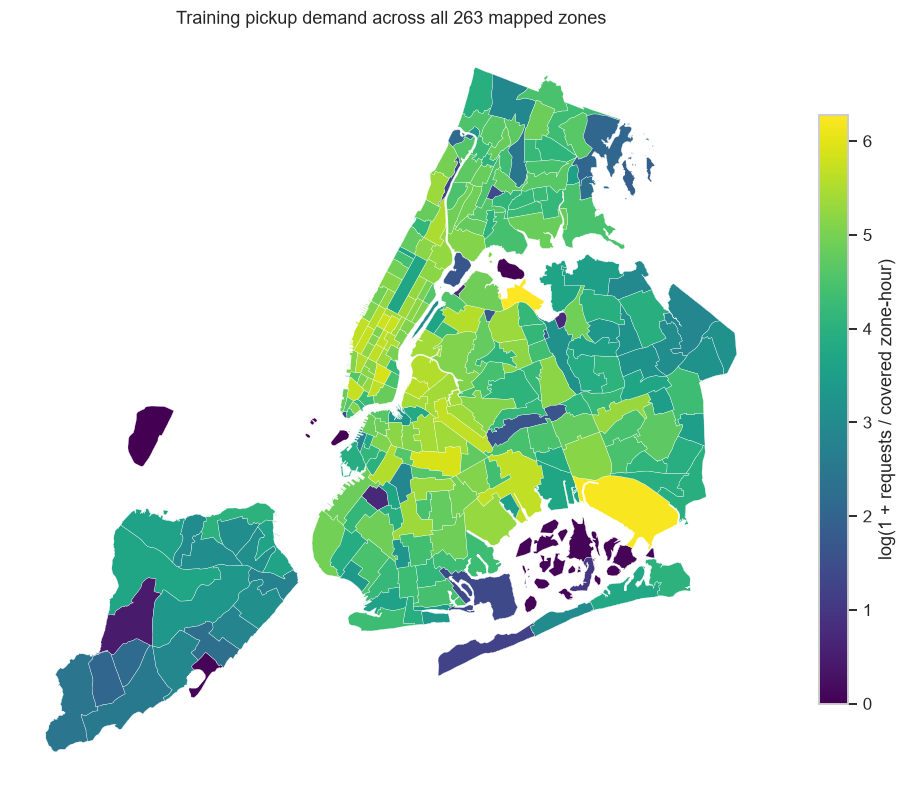

**Interpretation:** compare areas using the rate and coverage, not colour alone. These are operational counts per zone, not demand per resident or square kilometre. Different zone sizes and trip composition are not controlled by this map.

In [7]:
zone_summary = hours.groupby(['zone_id', 'zone_name', 'borough', 'is_airport'], observed=True).agg(
    requests=('request_count', lambda values: values.sum(min_count=1)), covered_hours=('request_count', 'count'),
    passenger_miles=('passenger_miles_sum', lambda values: values.sum(min_count=1)),
    passenger_minutes=('passenger_minutes_sum', lambda values: values.sum(min_count=1)),
    passenger_count=('passenger_measure_count', 'sum'),
    recorded_fare_usd=('valid_base_fare_sum_usd', lambda values: values.sum(min_count=1)),
    valid_fares=('valid_fare_count', 'sum')).reset_index()
zone_summary['mean_requests'] = divide_valid(zone_summary['requests'], zone_summary['covered_hours'])
zone_summary['mean_miles'] = divide_valid(zone_summary['passenger_miles'], zone_summary['passenger_count'])
zone_summary['mean_minutes'] = divide_valid(zone_summary['passenger_minutes'], zone_summary['passenger_count'])
zone_summary['mean_recorded_fare'] = divide_valid(zone_summary['recorded_fare_usd'], zone_summary['valid_fares'])
zone_summary = zone_summary.sort_values('mean_requests', ascending=False)
zone_summary['rate_share'] = zone_summary['mean_requests'] / zone_summary['mean_requests'].sum()
top_ten_share = float(zone_summary['rate_share'].head(10).sum())
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
zone_summary.head(20).iloc[::-1].plot.barh(x='zone_name', y='mean_requests', ax=axes[0], legend=False, color='#147d92')
axes[0].set(title='20 busiest pickup zones', xlabel='Requests / covered zone-hour', ylabel='Pickup zone')
cumulative = np.r_[0, zone_summary['rate_share'].cumsum().to_numpy()]
axes[1].plot(np.arange(len(cumulative)), cumulative * 100, label='Observed rate share')
axes[1].plot([0, len(zones)], [0, 100], '--', label='Equal-share reference')
axes[1].set(title='How concentrated is demand?', xlabel='Zones ranked busiest first', ylabel='Cumulative demand-rate share (%)')
axes[1].legend(); plt.tight_layout(); plt.show()
print(f'Top 10 of {len(zones)} zones account for {100 * top_ten_share:.2f}% of summed mean demand rates.')
zone_hour_demand = hours.groupby(['zone_id', 'hour_nyc'])['request_count'].mean().unstack()
top_zone_ids = zone_summary.head(20)['zone_id']
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(zone_hour_demand.reindex(top_zone_ids), cmap='YlGnBu', ax=ax,
            yticklabels=zone_summary.head(20)['zone_name'],
            cbar_kws={'label': 'Mean eligible requests / covered zone-hour'})
ax.set(title='Demand changes by both pickup zone and civil hour', xlabel='New York civil hour', ylabel='Pickup zone')
plt.tight_layout(); plt.show()

map_values = zones.merge(zone_summary[['zone_id', 'mean_requests']], on='zone_id', validate='one_to_one')
patches, patch_values = [], []
for row in map_values.itertuples():
    geometry = from_wkb(bytes(row.geometry_wkb))
    polygons = list(geometry.geoms) if geometry.geom_type == 'MultiPolygon' else [geometry]
    for polygon in polygons:
        polygon = orient(polygon, sign=1.0)
        rings = [polygon.exterior, *polygon.interiors]
        ring_paths = [PlotPath(np.asarray(ring.coords)) for ring in rings]
        patches.append(PathPatch(PlotPath.make_compound_path(*ring_paths)))
        patch_values.append(np.log1p(row.mean_requests))
fig, ax = plt.subplots(figsize=(9, 8))
collection = PatchCollection(patches, cmap='viridis', linewidth=.2, edgecolor='white')
collection.set_array(np.asarray(patch_values))
ax.add_collection(collection); ax.autoscale_view(); ax.set_aspect('equal'); ax.set_axis_off()
fig.colorbar(collection, ax=ax, shrink=.7, label='log(1 + requests / covered zone-hour)')
ax.set_title('Training pickup demand across all 263 mapped zones')
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation:** compare areas using the rate and coverage, not colour alone. '
                 'These are operational counts per zone, not demand per resident or square kilometre. '
                 'Different zone sizes and trip composition are not controlled by this map.'))


## 6. Distributions, journey characteristics and common pricing

The compact release has **hourly summaries, not individual trips**. The distributions
below therefore describe zone-hour counts and zone-hour mean journey lengths, not the
distribution of individual trip durations/fares. Individual-trip quantiles cannot be
reconstructed from means. The existing accepted-trip range remains 1 minute–3 hours.

Pooled mean distance/duration uses sums divided by contributing-trip counts, not an
unweighted mean of hourly means. Recorded fare is background only. Our eventual pricing
is `base_charge * served_trips + per_mile_rate * served_passenger_miles`; neither rate
is invented here, and no numeric profit result is calculated from these observations.


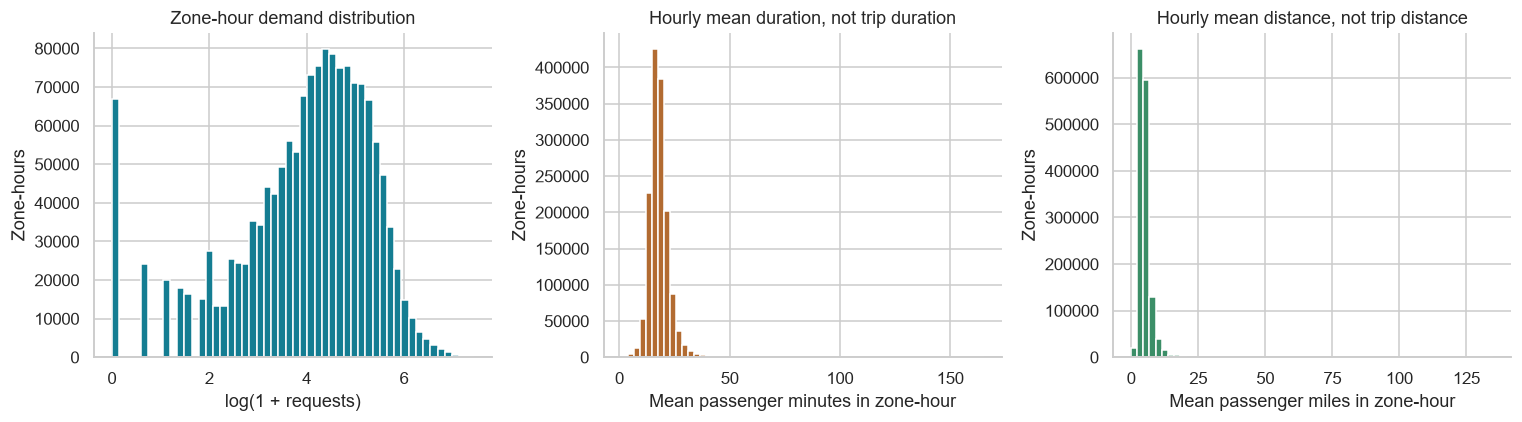

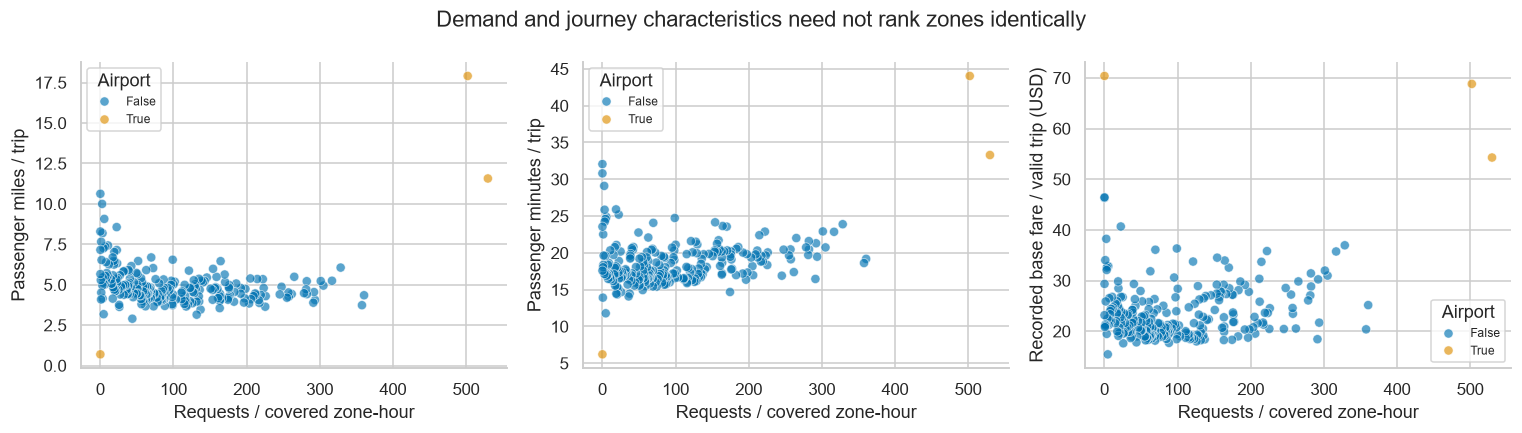

,Training pooled mean
passenger_miles_per_trip,5.001629
passenger_minutes_per_trip,19.692833
recorded_base_fare_per_valid_trip_usd,25.517229


**Decision implication:** a per-mile revenue rule does not make long journeys automatically optimal. Longer occupied trips reduce the number of future passengers a car can serve. Duration is an availability constraint, never a passenger time charge.

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(np.log1p(hours['request_count'].dropna()), bins=50, color='#147d92')
axes[0].set(xlabel='log(1 + requests)', ylabel='Zone-hours', title='Zone-hour demand distribution')
axes[1].hist(hours['mean_passenger_minutes'].dropna(), bins=60, color='#b26b31')
axes[1].set(xlabel='Mean passenger minutes in zone-hour', ylabel='Zone-hours', title='Hourly mean duration, not trip duration')
axes[2].hist(hours['mean_passenger_miles'].dropna(), bins=60, color='#3b8e67')
axes[2].set(xlabel='Mean passenger miles in zone-hour', ylabel='Zone-hours', title='Hourly mean distance, not trip distance')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, value, label in zip(axes, ['mean_miles', 'mean_minutes', 'mean_recorded_fare'],
                           ['Passenger miles / trip', 'Passenger minutes / trip', 'Recorded base fare / valid trip (USD)']):
    sns.scatterplot(data=zone_summary, x='mean_requests', y=value, hue='is_airport', ax=ax, alpha=.65)
    ax.set(xlabel='Requests / covered zone-hour', ylabel=label)
    ax.legend(title='Airport', fontsize=8)
plt.suptitle('Demand and journey characteristics need not rank zones identically')
plt.tight_layout(); plt.show()
weighted_means = {
    'passenger_miles_per_trip': float(hours['passenger_miles_sum'].sum() / hours['passenger_measure_count'].sum()),
    'passenger_minutes_per_trip': float(hours['passenger_minutes_sum'].sum() / hours['passenger_measure_count'].sum()),
    'recorded_base_fare_per_valid_trip_usd': float(hours['valid_base_fare_sum_usd'].sum() / hours['valid_fare_count'].sum())}
display(pd.Series(weighted_means, name='Training pooled mean').to_frame())
display(Markdown('**Decision implication:** a per-mile revenue rule does not make long journeys automatically '
                 'optimal. Longer occupied trips reduce the number of future passengers a car can serve. '
                 'Duration is an availability constraint, never a passenger time charge.'))


## 7. Weekly repetition and historical forecasts

Compare each zone/hour with the same civil hour on preceding matching weekdays.
Four-week forecasts require **all four prior values**; missing weeks do not become zero
and are not silently averaged over fewer weeks. Use a common finite evaluation sample
in June–August, wholly inside training. This is a baseline diagnostic, not model selection.

**MAE** is average absolute request error. **RMSE** penalises large errors more. **WAPE**
is total absolute error divided by total actual demand, so zero-demand rows do not cause
division by zero. An equal-share forecast uses the four-week predicted city total spread
across 263 zones; this is a demand reference, **not a simulated fleet or profit result**.


,MAE_requests,RMSE_requests,WAPE_percent,bias_requests
Same hour last week,17.258,36.575,17.320,0.294
Previous four matching weeks,14.073,29.033,14.123,1.672
Equal-share demand reference,71.148,105.661,71.403,1.672


Common evaluated hours: 2208 out of 2208 | zone-hour comparisons: 580704


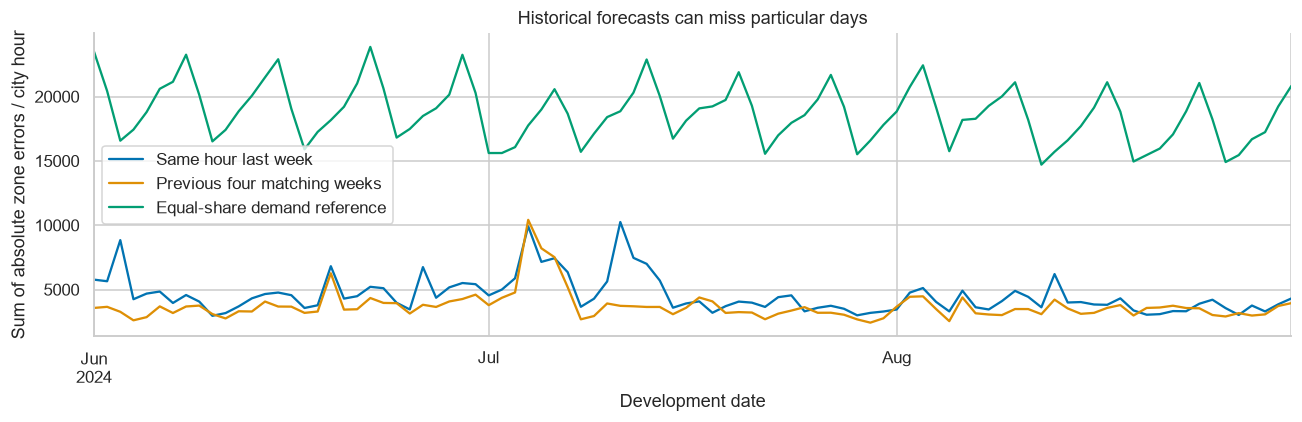

Zone demand-rank correlation, Jan–Apr vs May–Aug: 0.998
Median within-zone correlation with last week: 0.858 | zones with defined correlation: 261


**Measured finding:** **Previous four matching weeks** has the lower MAE on this internal development sample. This does not establish the best future forecast or the most profitable placement rule.

In [9]:
last_week, four_week = matching_week_forecasts(wide)
development_rows = (wide.index >= pd.Timestamp(DEVELOPMENT_START)) & (wide.index < pd.Timestamp(TRAIN_END))
common_hours = development_rows & wide.notna().all(axis=1) & last_week.notna().all(axis=1) & four_week.notna().all(axis=1)
actual = wide.loc[common_hours]
if actual.empty:
    raise ValueError('No common complete development hours; inspect coverage before scoring.')
four_prediction = four_week.loc[common_hours]
last_prediction = last_week.loc[common_hours]
equal_prediction = pd.DataFrame(np.repeat((four_prediction.sum(axis=1) / len(zones)).to_numpy()[:, None],
                                          len(zones), axis=1), index=actual.index, columns=actual.columns)
predictions = {'Same hour last week': last_prediction, 'Previous four matching weeks': four_prediction,
               'Equal-share demand reference': equal_prediction}
score_table = pd.DataFrame({name: forecast_scores(actual, frame) for name, frame in predictions.items()}).T
display(score_table.round(3))
print('Common evaluated hours:', len(actual), 'out of', int(development_rows.sum()),
      '| zone-hour comparisons:', actual.size)
baseline_daily = pd.DataFrame({name: (frame - actual).abs().sum(axis=1) for name, frame in predictions.items()})
baseline_daily = baseline_daily.groupby(baseline_daily.index.normalize()).mean()
baseline_daily.plot(figsize=(12, 4), ylabel='Sum of absolute zone errors / city hour', xlabel='Development date',
                    title='Historical forecasts can miss particular days')
plt.tight_layout(); plt.show()
rank_first = hours.loc[hours['event_date_nyc'] < '2024-05-01'].groupby('zone_id')['request_count'].mean()
rank_second = hours.loc[hours['event_date_nyc'] >= '2024-05-01'].groupby('zone_id')['request_count'].mean()
rank_correlation = float(stats.spearmanr(rank_first, rank_second).statistic)
weekly_correlation = wide.corrwith(last_week).dropna()
print('Zone demand-rank correlation, Jan–Apr vs May–Aug:', round(rank_correlation, 3))
print('Median within-zone correlation with last week:', round(float(weekly_correlation.median()), 3),
      '| zones with defined correlation:', len(weekly_correlation))
best_historical = score_table.loc[['Same hour last week', 'Previous four matching weeks'], 'MAE_requests'].idxmin()
display(Markdown(f'**Measured finding:** **{best_historical}** has the lower MAE on this internal development '
                 'sample. This does not establish the best future forecast or the most profitable placement rule.'))


## 8. Weather and holidays: descriptive associations

Count city hours once, not 263 times. Rain comparisons require a measured precipitation
value; missing and trace precipitation are not labelled dry. To reduce obvious calendar
mixing, subtract each month–weekday–hour mean demand before comparing wet and dry hours.
This is **not a causal estimate**: other differences and weather timing remain.

Holiday comparisons show each training holiday alongside non-holiday days with the same
month and weekday, using requests per real hour. Small comparison groups are shown,
not presented as strong evidence. Weather is observed retrospectively, not a proven
forecast-time predictor; a future model needs lagged weather or a verified forecast.


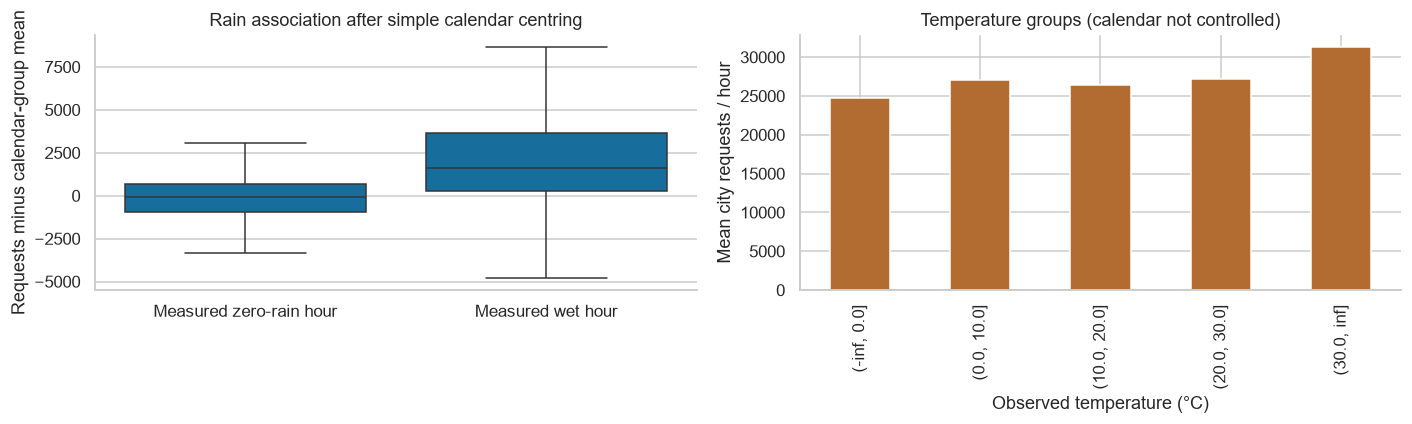

,mean,median,count
rain_group,,,
Measured wet hour,2087.361871,1622.500,490
Measured zero-rain hour,-204.561463,-93.475,5000


,date,holiday,holiday_requests_per_hour,matched_nonholiday_mean,comparison_days
0,2024-01-01,New Year's Day,26476.125000,22475.944444,3
1,2024-01-15,"Birthday of Martin Luther King, Jr.",23059.541667,22475.944444,3
2,2024-02-19,Washington's Birthday,22775.333333,23593.833333,3
3,2024-05-27,Memorial Day,21326.333333,23822.111111,3
4,2024-06-19,Juneteenth National Independence Day,24755.000000,26493.250000,3
5,2024-07-04,Independence Day,23183.166667,26246.944444,3


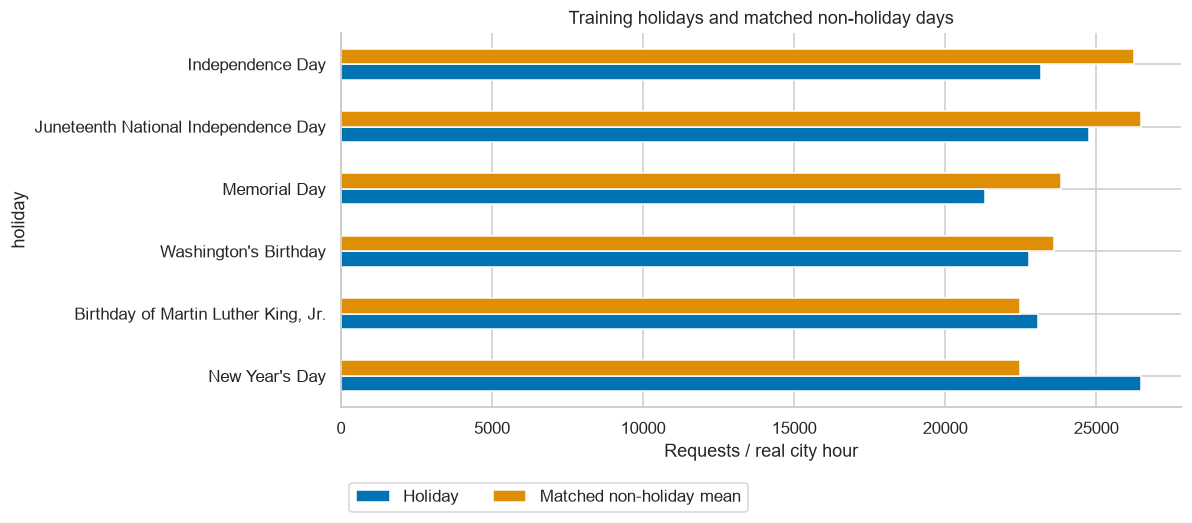

In [10]:
weather_city = city.dropna(subset=['requests', 'rain_mm']).copy()
weather_city['calendar_reference'] = weather_city.groupby(['month', 'weekday', 'hour'])['requests'].transform('mean')
weather_city['calendar_residual'] = weather_city['requests'] - weather_city['calendar_reference']
weather_city['rain_group'] = np.where(weather_city['rain_mm'] > 0, 'Measured wet hour', 'Measured zero-rain hour')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=weather_city, x='rain_group', y='calendar_residual', showfliers=False, ax=axes[0])
axes[0].set(xlabel='', ylabel='Requests minus calendar-group mean', title='Rain association after simple calendar centring')
temperature_bins = pd.cut(city['temperature_c'], bins=[-np.inf, 0, 10, 20, 30, np.inf])
temperature_summary = city.groupby(temperature_bins, observed=True)['requests'].agg(['mean', 'count'])
temperature_summary['mean'].plot.bar(ax=axes[1], color='#b26b31')
axes[1].set(xlabel='Observed temperature (°C)', ylabel='Mean city requests / hour', title='Temperature groups (calendar not controlled)')
plt.tight_layout(); plt.show()
display(weather_city.groupby('rain_group')['calendar_residual'].agg(['mean', 'median', 'count']))
holiday_rows = []
for day, row in daily.loc[daily['holiday'].fillna(False)].iterrows():
    controls = daily.loc[(daily.index.month == day.month) & (daily.index.day_of_week == day.day_of_week)
                         & ~daily['holiday'].fillna(False), 'requests_per_hour'].dropna()
    holiday_rows.append({'date': day.date().isoformat(), 'holiday': row['holiday_name'],
        'holiday_requests_per_hour': row['requests_per_hour'], 'matched_nonholiday_mean': controls.mean(),
        'comparison_days': len(controls)})
holiday_comparison = pd.DataFrame(holiday_rows)
display(holiday_comparison)
if not holiday_comparison.empty:
    holiday_comparison.set_index('holiday')[['holiday_requests_per_hour', 'matched_nonholiday_mean']].plot.barh(figsize=(11, 5))
    plt.legend(['Holiday', 'Matched non-holiday mean'], loc='upper left', bbox_to_anchor=(0, -.18), ncol=2)
    plt.xlabel('Requests / real city hour'); plt.title('Training holidays and matched non-holiday days')
    plt.tight_layout(); plt.show()


## 9. Pickup/drop-off imbalance and quieter zones

A positive pickup-minus-drop-off count suggests more passenger departures than arrivals
in an hour; it is not a measured empty-car shortage. Counts contain no vehicle IDs,
unserved requests, available fleet or charging state. Trip eligibility can differ for
pickups and drop-offs. Only use hours with both coverage flags complete.

For service considerations, define low/high demand zones by training mean request rate.
Report demand and baseline error separately; do not invent wait times, served shares,
income groups or an actual fairness outcome.


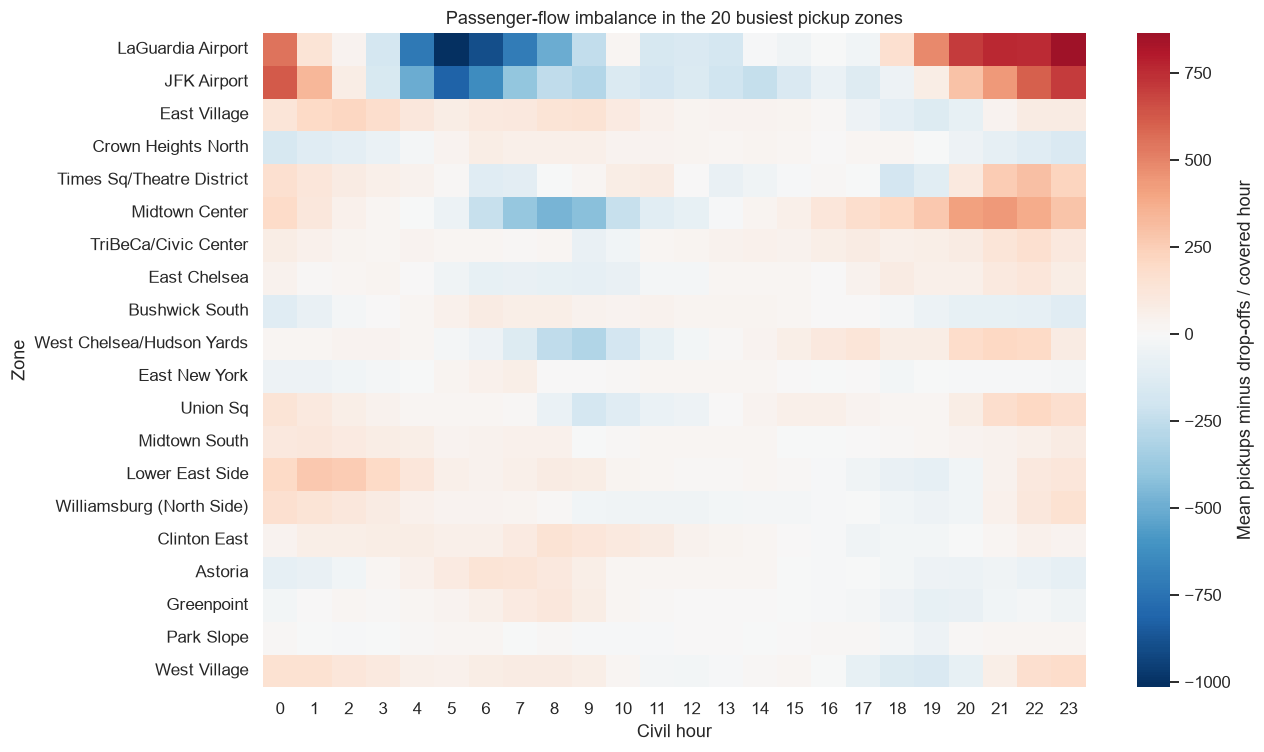

,zones,mean_requests_per_hour,mean_four_week_MAE
demand_group,,,
Low,66,14.405230,3.861540
Lower-middle,66,56.891344,8.494812
Upper-middle,65,111.015382,14.134138
High,66,227.314595,29.800838


**Interpretation:** low demand is not zero social value. The later simulator must report service outcomes across these groups under the same minimum-service rules. Observed demand and forecast error alone do not measure access or fairness.

In [11]:
activity = hours.loc[hours['pickup_coverage_complete'] & hours['dropoff_coverage_complete']].copy()
activity['net_pickups'] = activity['pickup_count'] - activity['dropoff_count']
net_by_hour = activity.groupby(['zone_name', 'hour_nyc'])['net_pickups'].mean().unstack()
top_zone_names = zone_summary.head(20)['zone_name']
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(net_by_hour.reindex(top_zone_names), center=0, cmap='RdBu_r', ax=ax,
            cbar_kws={'label': 'Mean pickups minus drop-offs / covered hour'})
ax.set(title='Passenger-flow imbalance in the 20 busiest pickup zones', xlabel='Civil hour', ylabel='Zone')
plt.tight_layout(); plt.show()
ranked = zone_summary.set_index('zone_id')['mean_requests'].rank(method='first')
zone_groups = pd.qcut(ranked, 4, labels=['Low', 'Lower-middle', 'Upper-middle', 'High'])
zone_errors = (four_prediction - actual).abs().mean(axis=0).rename('four_week_MAE')
service_summary = zone_summary.set_index('zone_id').join(zone_errors).assign(demand_group=zone_groups)
display(service_summary.groupby('demand_group', observed=True).agg(zones=('zone_name', 'size'),
    mean_requests_per_hour=('mean_requests', 'mean'), mean_four_week_MAE=('four_week_MAE', 'mean')))
display(Markdown('**Interpretation:** low demand is not zero social value. The later simulator must '
                 'report service outcomes across these groups under the same minimum-service rules. '
                 'Observed demand and forecast error alone do not measure access or fairness.'))


## 10. Revised H1: meaningful demand differences across zones and hours

**Spatial null:** zone demand-rate distributions are equal when comparing the same weeks.
**Temporal null:** city demand-rate distributions are equal across 24 civil hours when
comparing the same weeks. Both alternatives are that at least one category differs.
This tests operational counts per zone, not equal demand density or a causal place effect.

Use only complete **Monday–Sunday weeks with 168 real, covered hours in all 263 zones**.
This excludes the spring DST week and partial boundary weeks. Each week contributes one
mean per zone and one mean per clock hour. **Friedman's test** compares category ranks
within each week. Apply Bonferroni correction for the two omnibus tests. No hundreds of
unadjusted zone-pair tests are performed. Report **Kendall's W** (rank consistency) and
**share mismatch** (half the absolute difference between demand shares and equal shares).

The latter is a descriptive volume mismatch, not the fraction of cars to reposition or
profit improvement. Report two-week moving-block bootstrap intervals and sensitivity to
one-/four-week blocks. Weeks may remain dependent; holidays/trends and irregular missing
weeks weaken the uncertainty assumptions. Results are exploratory, not independent-trip
or causal proof. SciPy also warns against tiny Friedman samples; we require ≥12 weeks.
Only genuinely consecutive retained weeks can form a bootstrap block; do not bridge the
excluded DST week. Extremely small p-values can underflow numerically to zero; that is
reported as **below numerical precision**, never as a literally zero probability.

Classify revised H1 as **supported within this exploratory design** only if both adjusted
p-values are below 0.05 and both 95% mismatch lower bounds exceed the predeclared 10%
threshold. If both upper bounds are below it, call it **not supported at that threshold**;
otherwise **inconclusive**. Conclusions do not validate forecasting or profit superiority.

Method reference: [SciPy Friedman documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.friedmanchisquare.html).


In [12]:
zone_weeks, hour_weeks, retained_weeks = complete_week_matrices(wide)
h1_rows = []
for offset, (label, matrix) in enumerate([('Pickup zone', zone_weeks), ('Civil hour', hour_weeks)]):
    test = stats.friedmanchisquare(*matrix.T, nan_policy='raise')
    interval = block_share_interval(matrix, repeats=BOOTSTRAP_REPEATS, block_length=2,
                                   seed=RANDOM_SEED + offset, week_starts=retained_weeks)
    h1_rows.append({'comparison': label, 'weeks': len(matrix), 'categories': matrix.shape[1],
        'friedman_statistic': float(test.statistic), 'p_adjusted_two_tests': min(1.0, float(test.pvalue) * 2),
        'kendall_W': float(test.statistic / (len(matrix) * (matrix.shape[1] - 1))),
        'share_mismatch': share_mismatch(matrix.mean(axis=0)), 'mismatch_low_95': interval[0], 'mismatch_high_95': interval[1]})
h1_results = pd.DataFrame(h1_rows).set_index('comparison')
assert h1_results['kendall_W'].between(0, 1 + 1e-8).all()
display(h1_results)
if (h1_results['p_adjusted_two_tests'] == 0).any():
    print('A displayed p-value of 0 means below floating-point numerical precision, not literal zero.')
print('Retained complete weeks:', len(retained_weeks), '| first:', retained_weeks.min().date(),
      '| last:', retained_weeks.max().date(), '| DST and partial weeks excluded')
sensitivity_rows = []
for offset, (label, matrix) in enumerate([('Pickup zone', zone_weeks), ('Civil hour', hour_weeks)]):
    for length in [1, 2, 4]:
        low, high = block_share_interval(matrix, repeats=BOOTSTRAP_REPEATS, block_length=length,
                                        seed=RANDOM_SEED + offset, week_starts=retained_weeks)
        sensitivity_rows.append({'comparison': label, 'block_weeks': length, 'low_95': low, 'high_95': high})
display(pd.DataFrame(sensitivity_rows))
supported = ((h1_results['p_adjusted_two_tests'] < ALPHA)
             & (h1_results['mismatch_low_95'] > PRACTICAL_SHARE_GAP)).all()
not_supported = (h1_results['mismatch_high_95'] < PRACTICAL_SHARE_GAP).all()
h1_status = 'supported within this exploratory design' if supported else 'not supported at this threshold' if not_supported else 'inconclusive'
print('Revised H1:', h1_status)
for threshold in [.05, .10, .20]:
    print(f'Lower bounds exceed {threshold:.0%} in both comparisons:',
          bool((h1_results['mismatch_low_95'] > threshold).all()))
display(Markdown(f'**Conclusion:** revised H1 is **{h1_status}** under the stated weekly design and '
                 '10% practical convention. Uniform zone/hour demand is a reference, not a claim '
                 'that equal allocation must lose profit. Larger zones, providers, destinations '
                 'and completed-trip selection can contribute to the observed differences.'))


,weeks,categories,friedman_statistic,p_adjusted_two_tests,kendall_W,share_mismatch,mismatch_low_95,mismatch_high_95
comparison,,,,,,,,
Pickup zone,33,263,8612.662227,0.000000e+00,0.996144,0.340659,0.338997,0.342822
Civil hour,33,24,740.408485,2.684972e-141,0.975505,0.136395,0.134172,0.139128


A displayed p-value of 0 means below floating-point numerical precision, not literal zero.
Retained complete weeks: 33 | first: 2024-01-01 | last: 2024-08-19 | DST and partial weeks excluded


,comparison,block_weeks,low_95,high_95
0,Pickup zone,1,0.339026,0.342264
1,Pickup zone,2,0.338997,0.342822
2,Pickup zone,4,0.338869,0.343150
3,Civil hour,1,0.133347,0.139028
4,Civil hour,2,0.134172,0.139128
5,Civil hour,4,0.134020,0.139458


Revised H1: supported within this exploratory design
Lower bounds exceed 5% in both comparisons: True
Lower bounds exceed 10% in both comparisons: True
Lower bounds exceed 20% in both comparisons: False


**Conclusion:** revised H1 is **supported within this exploratory design** under the stated weekly design and 10% practical convention. Uniform zone/hour demand is a reference, not a claim that equal allocation must lose profit. Larger zones, providers, destinations and completed-trip selection can contribute to the observed differences.

## 11. What this evidence suggests for models and allocation

**A forecast predicts requests. Allocation decides where available cars wait.** They are
different components. The next notebook must compare forecasts chronologically, then
the simulator must compare allocation strategies under identical pricing and costs.

Candidate forecasts, not a selected winner:
1. Same hour last week and strict four-week matching-hour mean: transparent baselines.
2. A count regression with zone/calendar effects: an interpretable check on whether
   simple structure explains much of demand. Consider overdispersion, not only Poisson.
3. The proposal's gradient-boosted trees: evaluate nonlinear zone/time/lag interactions.
   Use validation for tuning; explain predictions later with the planned interpretation.

Only prediction-time inputs are allowed: zone, calendar known in advance, past demand,
and genuinely available weather inputs. Future drop-offs, realised fares/durations and
current-hour retrospective weather cannot silently enter the forecast. See the official
[gradient-boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting).

Later allocation baselines: (a) each available car independently chooses an allowed zone
uniformly, repeated with fixed seeds; (b) approximately equal car counts; (c) placement
proportional to historical demand; and (d) our forecast/profit-oriented placement.
Use the same fleet sizes, allowed zones and operating rules. First compare forecasts
through the same placement rule, then compare placement rules with the same forecast.

H2 launch-area choice, H3 profit vs ride-count placement, H4 forecast vs history and H5
reposition vs stay still require held-out fleet simulation. Total profit is the primary
outcome. Empty miles, idle time, requests served and service gaps are secondary outcomes.
Common base-plus-mile prices are not set here; there is no passenger time charge.


In [13]:
measured_findings = {
    'training_zone_hours': len(hours), 'training_real_hours': len(wide), 'mapped_zones': len(zones),
    'top_10_zone_demand_rate_share': top_ten_share,
    'zone_rank_correlation_first_vs_second_training_half': rank_correlation,
    'median_within_zone_last_week_correlation': float(weekly_correlation.median()),
    'best_historical_MAE_in_development': best_historical,
    'development_common_hours': len(actual), 'revised_H1_status': h1_status,
    'h1_practical_share_gap': PRACTICAL_SHARE_GAP,
    'pricing': 'Common base charge + common per-passenger-mile charge; no time charge; rates undecided',
    'profit_superiority_tested': False}
display(pd.Series(measured_findings, name='Measured findings and scope').to_frame())
display(Markdown('**Next decision:** evaluate the candidate forecasts on September–October using '
                 'the same coverage policy and prediction horizon. No winner is selected here. '
                 'Demand heterogeneity motivates testing informed placement; it does not prove a profit gain.'))


,Measured findings and scope
training_zone_hours,1539865
training_real_hours,5855
mapped_zones,263
top_10_zone_demand_rate_share,0.133263
zone_rank_correlation_first_vs_second_training_half,0.997539
median_within_zone_last_week_correlation,0.857923
best_historical_MAE_in_development,Previous four matching weeks
development_common_hours,2208
revised_H1_status,supported within this exploratory design
h1_practical_share_gap,0.1


**Next decision:** evaluate the candidate forecasts on September–October using the same coverage policy and prediction horizon. No winner is selected here. Demand heterogeneity motivates testing informed placement; it does not prove a profit gain.

## 12. Save a small audit and final validation

An **audit** records which data, settings and results produced this notebook. Save small
summaries under ignored `data/eda/`; keep readable figures and results in the notebook
for grading. No raw data, simulator result or trained model is created here.

Limitations to carry into the report: completed-trip demand proxy; cleaning/provider
selection; missing weather and unresolved times; absence of individual-trip distributions
in this release; unequal zone sizes; retrospective weather; exploratory H1 assumptions;
and no established robotaxi prices, waits or service outcomes. The revised H1 and revenue
assumption remain a documented deviation pending team review.


In [14]:
assert hours['event_date_nyc'].between(pd.Timestamp(TRAIN_START), pd.Timestamp(TRAIN_END) - pd.Timedelta(days=1)).all()
assert wide.columns.is_unique and wide.index.is_unique
assert all(frame.index.equals(actual.index) and frame.columns.equals(actual.columns) for frame in predictions.values())
assert not h1_results.isna().any().any()
for label, matrix in [('zones', zone_weeks), ('hours', hour_weeks)]:
    assert np.isfinite(matrix).all() and (matrix >= 0).all(), label
score_table.to_csv(OUTPUT / 'historical_forecast_scores.csv')
h1_results.to_csv(OUTPUT / 'revised_h1_results.csv')
zone_summary.to_csv(OUTPUT / 'training_zone_summary.csv', index=False)
summary = {'created_at_utc': datetime.now(UTC).isoformat(), 'release': 'phase1-2024-v1',
    'python': sys.version.split()[0], 'versions': VERSIONS, 'training_start': TRAIN_START,
    'training_end_exclusive': TRAIN_END, 'development_start': DEVELOPMENT_START,
    'seed': RANDOM_SEED, 'bootstrap_repeats': BOOTSTRAP_REPEATS,
    'findings': measured_findings, 'H1': h1_results.reset_index().to_dict(orient='records'),
    'forecast_scores': score_table.reset_index(names='baseline').to_dict(orient='records'),
    'full_notebook_validation': 'All cells reached final validation in this run'}
(OUTPUT / 'eda_summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False), encoding='utf-8')
print('PASS: chronological boundaries, common benchmark sample, unique keys, finite H1 inputs and output summaries.')
print('Run finished. Saved small summaries under data/eda/phase2-training/.')


PASS: chronological boundaries, common benchmark sample, unique keys, finite H1 inputs and output summaries.
Run finished. Saved small summaries under data/eda/phase2-training/.
